In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.pricing import (
    black_scholes_call,
    monte_carlo_call,
    monte_carlo_call_antithetic
)

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

prix_reference = black_scholes_call(S0, K, T, r, sigma)

print("Prix Black-Scholes :", prix_reference)



Prix Black-Scholes : 10.450583572185565


In [5]:
n_values = [100, 500, 1000, 5000, 10000, 50000, 100000]

results = []

for N in n_values:

    # Monte-Carlo standard
    standard = monte_carlo_call(
        S0, K, T, r, sigma,
        n_simulations=N,
        seed=42
    )

    # Monte-Carlo antithétique
    antithetic = monte_carlo_call_antithetic(
        S0, K, T, r, sigma,
        n_pairs=N // 2,
        seed=42
    )

    results.append({
        "N": N,
        "Prix standard": standard["price"],
        "Prix antithétique": antithetic["price"],
        "Erreur standard": standard["standard_error"],
        "Erreur antithétique": antithetic["standard_error"]
    })

df = pd.DataFrame(results)

display(df)

,N,Prix standard,Prix antithétique,Erreur standard,Erreur antithétique
0,100,7.825768,8.286818,1.011962,0.733399
1,500,9.868363,9.843097,0.635871,0.433104
2,1000,9.911980,10.000398,0.448345,0.313601
3,5000,10.168920,10.450949,0.205861,0.150468
4,10000,10.345182,10.410052,0.147663,0.104872
5,50000,10.457692,10.454935,0.066143,0.046749
6,100000,10.420541,10.467314,0.046770,0.033077


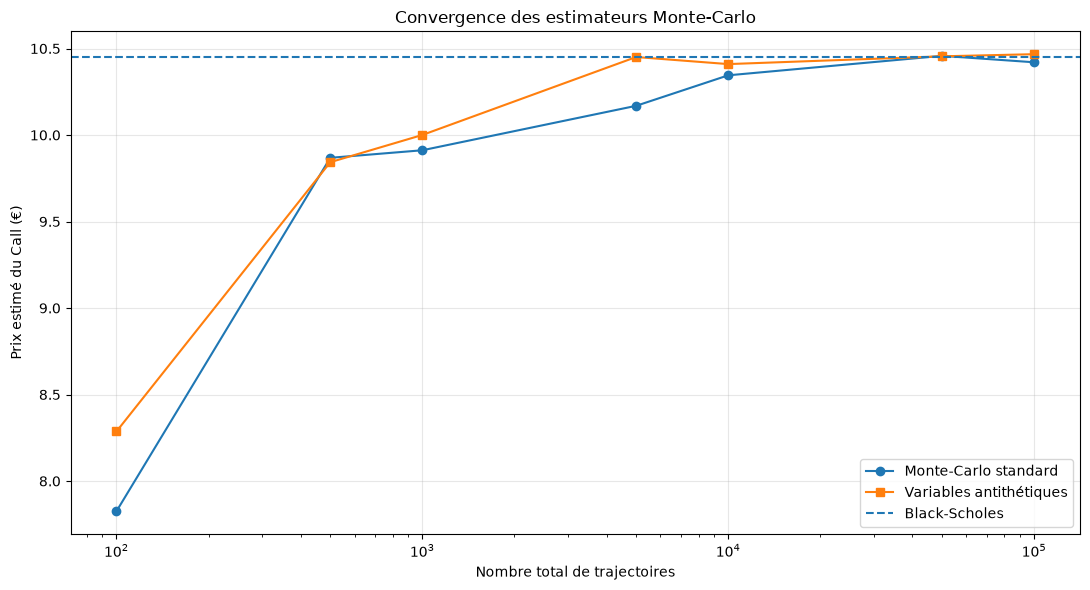

In [6]:

plt.figure(figsize=(11, 6))

plt.plot(
    df["N"],
    df["Prix standard"],
    marker="o",
    label="Monte-Carlo standard"
)

plt.plot(
    df["N"],
    df["Prix antithétique"],
    marker="s",
    label="Variables antithétiques"
)

plt.axhline(
    y=prix_reference,
    linestyle="--",
    label="Black-Scholes"
)

plt.xscale("log")

plt.xlabel("Nombre total de trajectoires")
plt.ylabel("Prix estimé du Call (€)")

plt.title("Convergence des estimateurs Monte-Carlo")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../figures/convergence_monte_carlo.png", dpi=300)
plt.show()


In [13]:
from src.pricing import monte_carlo_asian_call

asian = monte_carlo_asian_call(
    S0=100,
    K=100,
    T=1,
    r=0.05,
    sigma=0.20,
    n_simulations=50_000,
    n_steps=252,
    seed=42
)

print("Prix du Call asiatique :", asian["price"])
print("Erreur standard :", asian["standard_error"])
print("Intervalle de confiance :", asian["confidence_interval"])

Prix du Call asiatique : 5.838918415222987
Erreur standard : 0.03602069975020574
Intervalle de confiance : (5.768317843712584, 5.90951898673339)


In [14]:
from src.pricing import monte_carlo_asian_call

asian = monte_carlo_asian_call(
    S0=100,
    K=100,
    T=1,
    r=0.05,
    sigma=0.20,
    n_simulations=50_000,
    n_steps=252,
    seed=42
)

print("PRICING OPTION ASIATIQUE")
print("------------------------")
print("Prix :", round(asian["price"], 6))
print("Erreur standard :", round(asian["standard_error"], 6))
print("IC 95 % :", asian["confidence_interval"])

PRICING OPTION ASIATIQUE
------------------------
Prix : 5.838918
Erreur standard : 0.036021
IC 95 % : (5.768317843712584, 5.90951898673339)


In [16]:
european = black_scholes_call(
    100, 100, 1, 0.05, 0.20
)

print("Call européen :", round(european, 6))
print("Call asiatique :", round(asian["price"], 6))

print(
    "Différence :",
    round(european - asian["price"], 6)
)

Call européen : 10.450584
Call asiatique : 5.838918
Différence : 4.611665


In [17]:
from src.pricing import (
    black_scholes_call,
    monte_carlo_asian_call
)

# Paramètres du marché
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

# Prix européen
european = black_scholes_call(
    S0, K, T, r, sigma
)

# Prix asiatique
asian = monte_carlo_asian_call(
    S0, K, T, r, sigma,
    n_simulations=100_000,
    n_steps=252,
    seed=42
)

print("PRICING COMPARATIF")
print("--------------------------")
print("Call européen :", round(european, 6))
print("Call asiatique :", round(asian["price"], 6))
print("Erreur standard :", round(asian["standard_error"], 6))
print("IC 95 % :", asian["confidence_interval"])
print("Différence :", round(european - asian["price"], 6))

PRICING COMPARATIF
--------------------------
Call européen : 10.450584
Call asiatique : 5.786512
Erreur standard : 0.025338
IC 95 % : (5.736849828012812, 5.836173953258334)
Différence : 4.664072


In [18]:
steps_values = [12, 52, 252]

asian_results = []

for steps in steps_values:

    result = monte_carlo_asian_call(
        S0, K, T, r, sigma,
        n_simulations=100_000,
        n_steps=steps,
        seed=42
    )

    asian_results.append({
        "Observations": steps,
        "Prix asiatique": result["price"],
        "Erreur standard": result["standard_error"]
    })

df_asian = pd.DataFrame(asian_results)

display(df_asian)

,Observations,Prix asiatique,Erreur standard
0,12,6.164991,0.026990
1,52,5.910310,0.025893
2,252,5.786512,0.025338


In [23]:
from src.greeks import delta_call, delta_put

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

call_delta = delta_call(S0, K, T, r, sigma)
put_delta = delta_put(S0, K, T, r, sigma)

print("CALL DELTA :", call_delta)
print("PUT DELTA :", put_delta)
print("Somme des Deltas :", call_delta - put_delta)

CALL DELTA : 0.6368306511756191
PUT DELTA : -0.3631693488243809
Somme des Deltas : 1.0


In [30]:
from src.greeks import gamma

gamma_value = gamma(100, 100, 1, 0.05, 0.20)

print("GAMMA :", gamma_value)

GAMMA : 0.018762017345846895


In [31]:
from src.pricing import black_scholes_call

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

h = 0.01

gamma_numerical = (
    black_scholes_call(S0+h, K, T, r, sigma)
    - 2*black_scholes_call(S0, K, T, r, sigma)
    + black_scholes_call(S0-h, K, T, r, sigma)
) / h**2

gamma_analytical = gamma(S0, K, T, r, sigma)

print("Gamma analytique :", gamma_analytical)
print("Gamma numérique :", gamma_numerical)
print("Erreur :", abs(gamma_analytical-gamma_numerical))

Gamma analytique : 0.018762017345846895
Gamma numérique : 0.018762017077733617
Erreur : 2.681132781068296e-10


In [34]:
from src.greeks import vega

vega_value = vega(100, 100, 1, 0.05, 0.20)

print("VEGA :", vega_value)
print("VEGA par point de volatilité :", vega_value / 100)

VEGA : 37.52403469169379
VEGA par point de volatilité : 0.3752403469169379


In [35]:
from src.pricing import black_scholes_call
from src.greeks import vega

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

h = 0.0001

vega_numerical = (
    black_scholes_call(S0, K, T, r, sigma+h)
    - black_scholes_call(S0, K, T, r, sigma-h)
) / (2*h)

vega_analytical = vega(S0, K, T, r, sigma)

print("Vega analytique :", vega_analytical)
print("Vega numérique :", vega_numerical)
print("Erreur :", abs(vega_analytical-vega_numerical))

Vega analytique : 37.52403469169379
Vega numérique : 37.52403438721075
Erreur : 3.0448304499941514e-07


In [39]:
tc = greeks.theta_call(100, 100, 1, 0.05, 0.20)
tp = greeks.theta_put(100, 100, 1, 0.05, 0.20)

print("THETA CALL :", tc)
print("THETA PUT :", tp)

THETA CALL : -6.414027546438197
THETA PUT : -1.657880423934626


In [40]:

from src.pricing import black_scholes_call, black_scholes_put
from src.greeks import theta_call, theta_put

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

h = 0.0001

# Theta numérique du Call
theta_call_num = (
    black_scholes_call(S0, K, T-h, r, sigma)
    - black_scholes_call(S0, K, T+h, r, sigma)
) / (2*h)

# Theta numérique du Put
theta_put_num = (
    black_scholes_put(S0, K, T-h, r, sigma)
    - black_scholes_put(S0, K, T+h, r, sigma)
) / (2*h)

# Theta analytique
theta_call_ana = theta_call(S0, K, T, r, sigma)
theta_put_ana = theta_put(S0, K, T, r, sigma)

print("CALL")
print("Analytique :", theta_call_ana)
print("Numérique :", theta_call_num)
print("Erreur :", abs(theta_call_ana-theta_call_num))

print("\nPUT")
print("Analytique :", theta_put_ana)
print("Numérique :", theta_put_num)
print("Erreur :", abs(theta_put_ana-theta_put_num))


CALL
Analytique : -6.414027546438197
Numérique : -6.414027551358004
Erreur : 4.919806784187131e-09

PUT
Analytique : -1.657880423934626
Numérique : -1.6578804288513993
Erreur : 4.916773210794645e-09


In [43]:
from src.greeks import rho_call, rho_put

rho_c = rho_call(100, 100, 1, 0.05, 0.20)
rho_p = rho_put(100, 100, 1, 0.05, 0.20)

print("RHO CALL :", rho_c)
print("RHO PUT :", rho_p)

print("RHO CALL par 1% :", rho_c / 100)
print("RHO PUT par 1% :", rho_p / 100)

RHO CALL : 53.232481545376345
RHO PUT : -41.89046090469506
RHO CALL par 1% : 0.5323248154537634
RHO PUT par 1% : -0.4189046090469506


In [44]:

from src.pricing import black_scholes_call, black_scholes_put
from src.greeks import rho_call, rho_put

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

h = 0.0001

# Rho numérique Call
rho_call_num = (
    black_scholes_call(S0, K, T, r+h, sigma)
    - black_scholes_call(S0, K, T, r-h, sigma)
) / (2*h)

# Rho numérique Put
rho_put_num = (
    black_scholes_put(S0, K, T, r+h, sigma)
    - black_scholes_put(S0, K, T, r-h, sigma)
) / (2*h)

# Rho analytique
rho_call_ana = rho_call(S0, K, T, r, sigma)
rho_put_ana = rho_put(S0, K, T, r, sigma)

print("CALL")
print("Analytique :", rho_call_ana)
print("Numérique :", rho_call_num)
print("Erreur :", abs(rho_call_ana-rho_call_num))

print("\nPUT")
print("Analytique :", rho_put_ana)
print("Numérique :", rho_put_num)
print("Erreur :", abs(rho_put_ana-rho_put_num))


CALL
Analytique : 53.232481545376345
Numérique : 53.23248077413467
Erreur : 7.712416731919802e-07

PUT
Analytique : -41.89046090469506
Numérique : -41.89046183441292
Erreur : 9.297178564793285e-07


In [47]:
from src.greeks import calculate_greeks
import pandas as pd

call_greeks = calculate_greeks(
    100, 100, 1, 0.05, 0.20,
    option_type="call"
)

put_greeks = calculate_greeks(
    100, 100, 1, 0.05, 0.20,
    option_type="put"
)

df_greeks = pd.DataFrame({
    "Call": call_greeks,
    "Put": put_greeks
})

display(df_greeks)

,Call,Put
Delta,0.636831,-0.363169
Gamma,0.018762,0.018762
Vega,37.524035,37.524035
Theta,-6.414028,-1.657880
Rho,53.232482,-41.890461


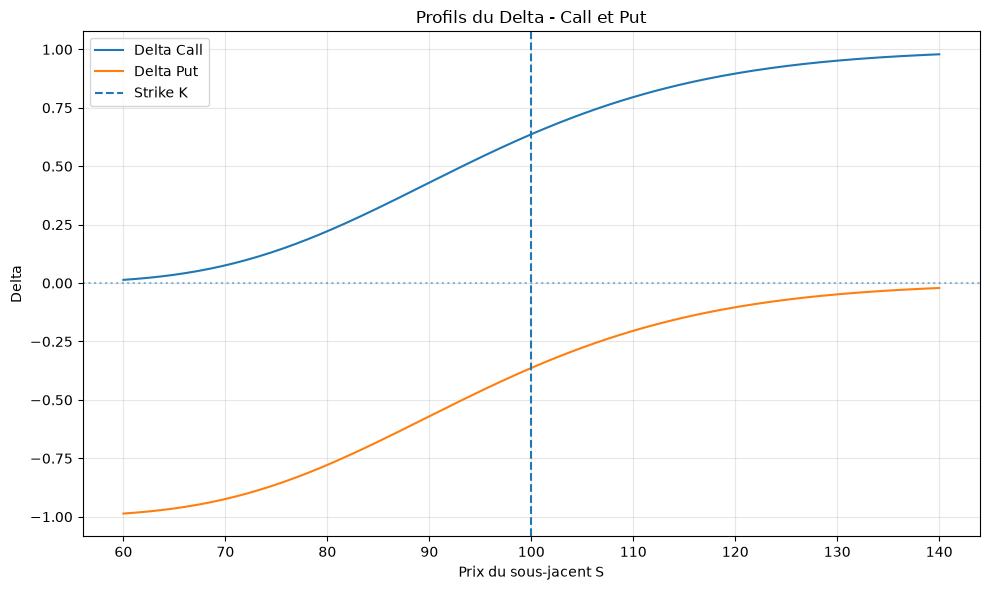

In [48]:

import numpy as np
import matplotlib.pyplot as plt

from src.greeks import delta_call, delta_put

# Paramètres
K = 100
T = 1
r = 0.05
sigma = 0.20

# Prix du sous-jacent
S_values = np.linspace(60, 140, 200)

# Calcul des Deltas
call_deltas = [
    delta_call(S, K, T, r, sigma)
    for S in S_values
]

put_deltas = [
    delta_put(S, K, T, r, sigma)
    for S in S_values
]

# Graphique
plt.figure(figsize=(10, 6))

plt.plot(
    S_values,
    call_deltas,
    label="Delta Call"
)

plt.plot(
    S_values,
    put_deltas,
    label="Delta Put"
)

plt.axvline(
    K,
    linestyle="--",
    label="Strike K"
)

plt.axhline(0, linestyle=":", alpha=0.5)

plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Delta")

plt.title("Profils du Delta - Call et Put")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/delta_profile.png", dpi=300)
plt.show()


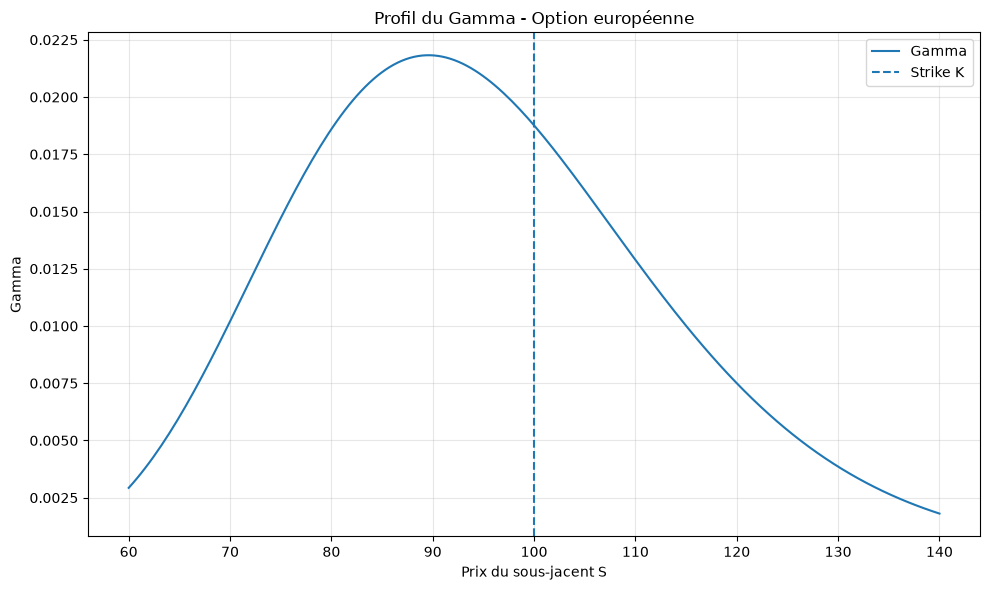

In [49]:

import numpy as np
import matplotlib.pyplot as plt

from src.greeks import gamma

# Paramètres
K = 100
T = 1
r = 0.05
sigma = 0.20

# Prix du sous-jacent
S_values = np.linspace(60, 140, 200)

# Calcul du Gamma
gamma_values = [
    gamma(S, K, T, r, sigma)
    for S in S_values
]

# Graphique
plt.figure(figsize=(10, 6))

plt.plot(
    S_values,
    gamma_values,
    label="Gamma"
)

plt.axvline(
    K,
    linestyle="--",
    label="Strike K"
)

plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Gamma")

plt.title("Profil du Gamma - Option européenne")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/gamma_profile.png", dpi=300)
plt.show()


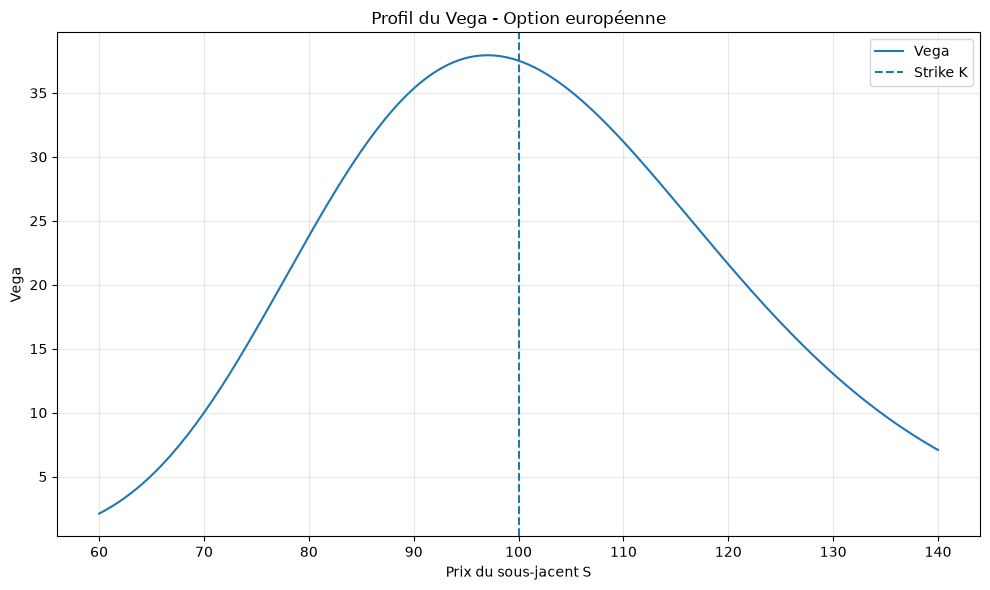

In [50]:

import numpy as np
import matplotlib.pyplot as plt

from src.greeks import vega

# Paramètres
K = 100
T = 1
r = 0.05
sigma = 0.20

# Prix du sous-jacent
S_values = np.linspace(60, 140, 200)

# Calcul du Vega
vega_values = [
    vega(S, K, T, r, sigma)
    for S in S_values
]

# Graphique
plt.figure(figsize=(10, 6))

plt.plot(
    S_values,
    vega_values,
    label="Vega"
)

plt.axvline(
    K,
    linestyle="--",
    label="Strike K"
)

plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Vega")

plt.title("Profil du Vega - Option européenne")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/vega_profile.png", dpi=300)
plt.show()


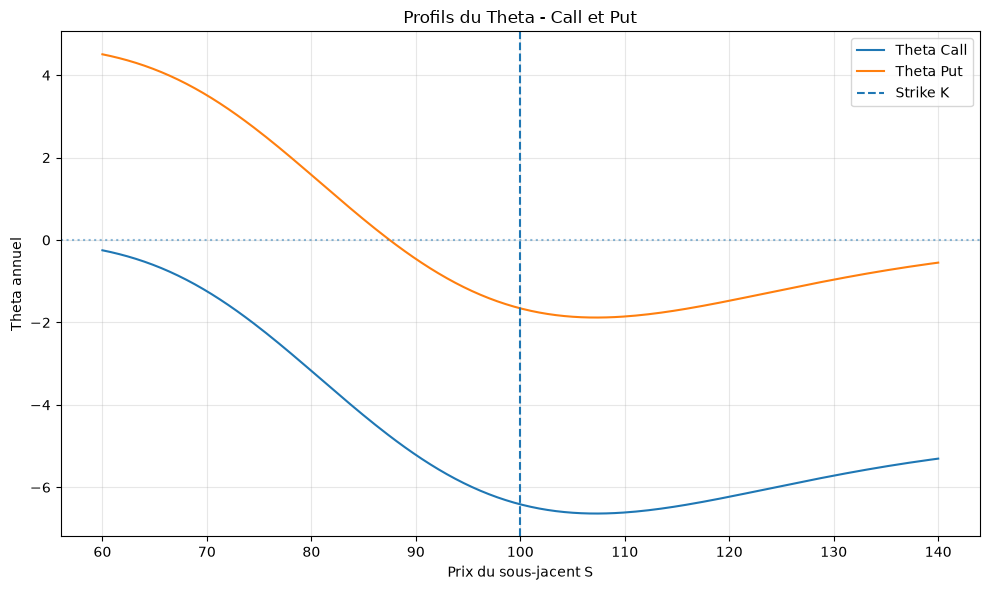

In [51]:

import numpy as np
import matplotlib.pyplot as plt

from src.greeks import theta_call, theta_put

# Paramètres
K = 100
T = 1
r = 0.05
sigma = 0.20

# Prix du sous-jacent
S_values = np.linspace(60, 140, 200)

# Calcul des Theta
call_theta_values = [
    theta_call(S, K, T, r, sigma)
    for S in S_values
]

put_theta_values = [
    theta_put(S, K, T, r, sigma)
    for S in S_values
]

# Graphique
plt.figure(figsize=(10, 6))

plt.plot(
    S_values,
    call_theta_values,
    label="Theta Call"
)

plt.plot(
    S_values,
    put_theta_values,
    label="Theta Put"
)

plt.axvline(
    K,
    linestyle="--",
    label="Strike K"
)

plt.axhline(0, linestyle=":", alpha=0.5)

plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Theta annuel")

plt.title("Profils du Theta - Call et Put")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/theta_profile.png", dpi=300)
plt.show()


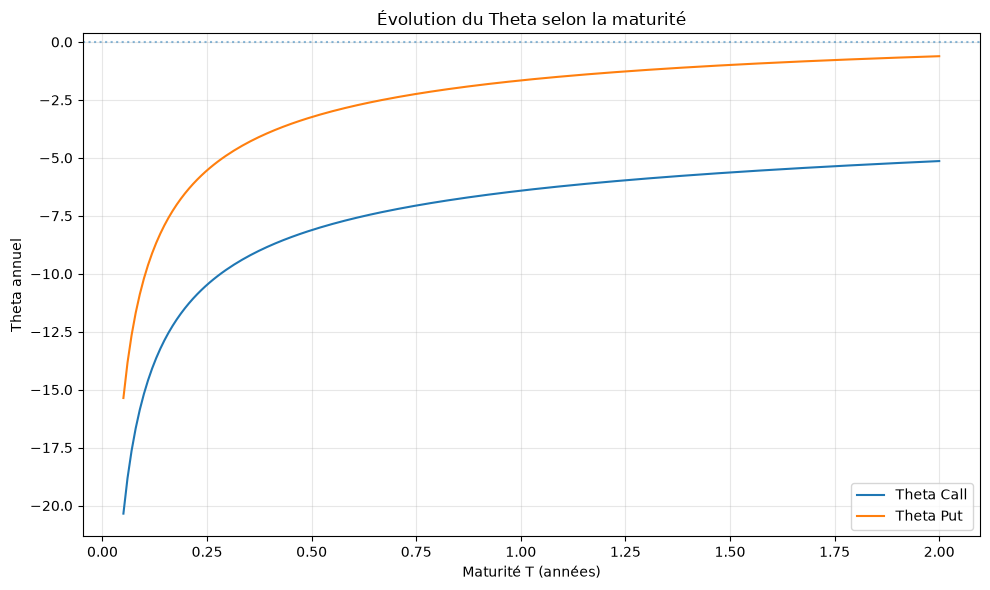

In [52]:

import numpy as np
import matplotlib.pyplot as plt

from src.greeks import theta_call, theta_put

# Paramètres
S0 = 100
K = 100
r = 0.05
sigma = 0.20

# Maturités en années
T_values = np.linspace(0.05, 2, 200)

# Calcul des Theta
call_theta_values = [
    theta_call(S0, K, T, r, sigma)
    for T in T_values
]

put_theta_values = [
    theta_put(S0, K, T, r, sigma)
    for T in T_values
]

# Graphique
plt.figure(figsize=(10, 6))

plt.plot(
    T_values,
    call_theta_values,
    label="Theta Call"
)

plt.plot(
    T_values,
    put_theta_values,
    label="Theta Put"
)

plt.axhline(0, linestyle=":", alpha=0.5)

plt.xlabel("Maturité T (années)")
plt.ylabel("Theta annuel")

plt.title("Évolution du Theta selon la maturité")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/theta_maturity.png", dpi=300)
plt.show()
